# Task 4: Count the cars. Instance segmentation with Mask R-CNN and YOLO-seg

**Goal.** Find **every car in a parking lot separately**: each car gets its own box, its own mask and its own number. U-Net would paint all cars with one colour; here we can **count** them. We train **two instance models on the same data** (a two-stage one, Mask R-CNN, and a one-stage one, YOLO-seg) and compare them.

**Data.** [NDISPark (Night and Day Instance Segmented Park)](https://zenodo.org/records/6560823): about 250 images of parking areas, every car labelled with a pixel mask (Open Data Commons Attribution licence). The **training images were taken by day, the validation images by night**: the model must work in light it has not seen. It is small on purpose: we **fine-tune** models that already know COCO instead of training from zero.

## 0. Setup
Torchvision comes with Colab. `pycocotools` reads the COCO annotation files.

In [ ]:
# [colab-only] pycocotools reads COCO annotation files; ultralytics is the YOLO library
!pip -q install pycocotools ultralytics

In [ ]:
import os, io, glob, json, random, time, zipfile, hashlib, shutil, urllib.request
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from pycocotools.coco import COCO
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import contextlib
from pycocotools import mask as mask_util
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- settings you can change ----
EPOCHS      = 8
BATCH_SIZE  = 2
LR          = 0.005
NUM_CLASSES = 2        # background + car
MIN_SIZE, MAX_SIZE = 640, 1066     # the model resizes images to this range (smaller = faster)

# YOLO-seg settings (section 6)
YOLO_WEIGHTS = "yolo11n-seg.pt"    # the smallest YOLO11 segmentation model, pretrained on COCO
YOLO_EPOCHS  = 30
YOLO_IMGSZ   = 640
YOLO_BATCH   = 8

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("No GPU. In Colab: Runtime > Change runtime type > T4 GPU, then run again.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
device: cuda


## 1. Download and look at the data

In [ ]:
# [colab-only] download the NDISPark dataset from Zenodo (about 118 MB)
URL = "https://zenodo.org/records/6560823/files/ndis_park.zip?download=1"
MD5 = "2825a2403794d233c278e2532d061359"          # checksum listed on the Zenodo page
ROOT = "ndis_park"
if not os.path.exists("ndis_park.zip"):
    # Using wget to bypass urllib 403 block
    import subprocess
    print("Downloading dataset...")
    subprocess.run(["wget", "-O", "ndis_park.zip", URL], check=True)
md5 = hashlib.md5(open("ndis_park.zip", "rb").read()).hexdigest()
print("md5 matches the Zenodo page:", md5 == MD5)
with zipfile.ZipFile("ndis_park.zip") as z:
    z.extractall(ROOT)

md5 matches the Zenodo page: True


In [ ]:
# The zip holds images and COCO annotation files. We look the files up by name, so the folder layout does not matter.
def find(name):
    hits = glob.glob(os.path.join(ROOT, "**", name), recursive=True)
    assert hits, f"{name} not found inside {ROOT}"
    return hits[0]

img_index = {os.path.basename(p): p for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True)
             if p.lower().endswith((".jpg", ".jpeg", ".png"))}
coco_train = COCO(find("train_coco_annotations.json"))      # daytime images
coco_val   = COCO(find("val_coco_annotations.json"))        # night-time images

def usable_ids(coco):
    return sorted(i for i in coco.imgs if coco.getAnnIds(imgIds=i))      # keep images with at least one car

train_ids, val_ids = usable_ids(coco_train), usable_ids(coco_val)
def path_of(coco, i):
    return img_index[os.path.basename(coco.imgs[i]["file_name"])]

n_train = [len(coco_train.getAnnIds(imgIds=i)) for i in train_ids]
n_val   = [len(coco_val.getAnnIds(imgIds=i)) for i in val_ids]
print(f"train (day):  {len(train_ids)} images, {sum(n_train)} cars, {np.mean(n_train):.1f} per image")
print(f"val (night):  {len(val_ids)} images, {sum(n_val)} cars, {np.mean(n_val):.1f} per image")
print("categories:", [c["name"] for c in coco_train.cats.values()])

loading annotations into memory...
Done (t=0.76s)
creating index...
index created!
loading annotations into memory...
Done (t=0.21s)
creating index...
index created!
train (day):  111 images, 2577 cars, 23.2 per image
val (night):  30 images, 725 cars, 24.2 per image
categories: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell p

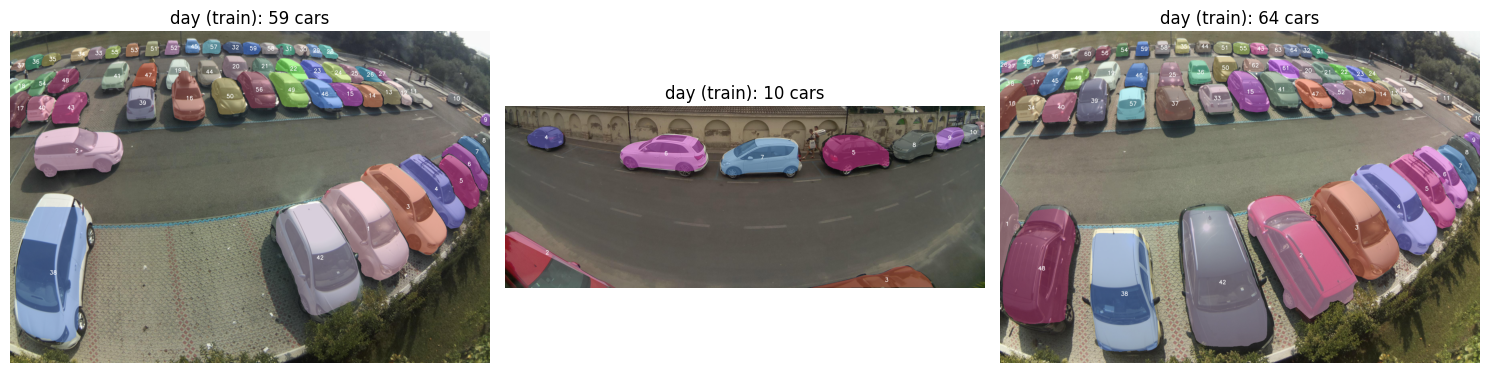

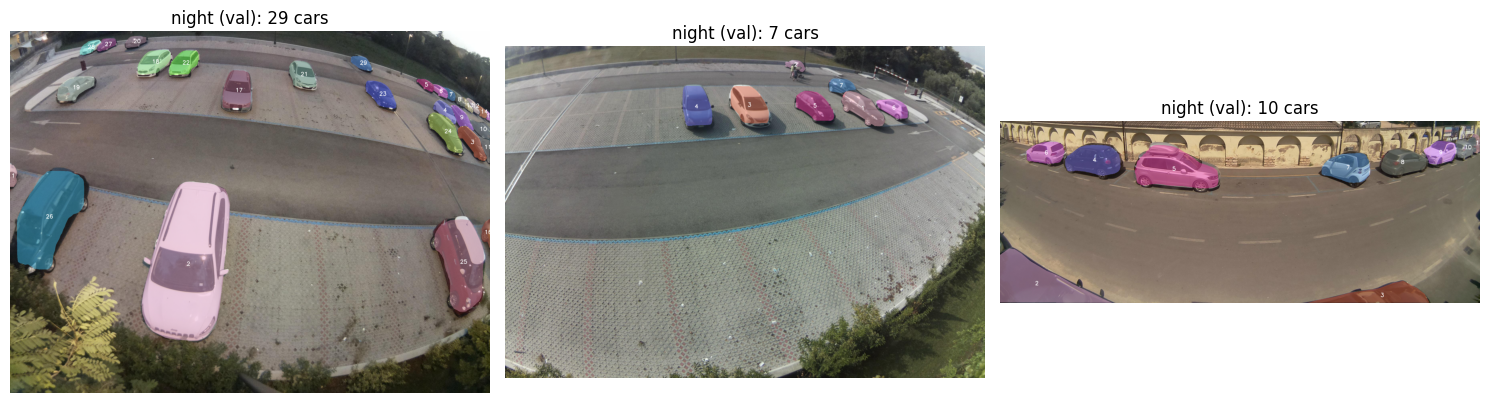

In [ ]:
def draw_instances(img, masks, number=True):
    """img: HxWx3 uint8 RGB. Every instance gets its own colour and a number."""
    out = img.copy().astype(np.float32)
    rng = np.random.default_rng(7)
    for m in masks:
        color = rng.integers(60, 255, 3).astype(np.float32)
        out[m] = 0.5 * out[m] + 0.5 * color
    out = np.ascontiguousarray(out.clip(0, 255).astype(np.uint8))       # putText needs uint8
    if number:
        for n, m in enumerate(masks):
            ys, xs = np.where(m)
            if len(xs):
                cv2.putText(out, str(n + 1), (int(xs.mean()) - 8, int(ys.mean()) + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    return out

def show_coco(coco, ids, title):
    fig, ax = plt.subplots(1, len(ids), figsize=(5 * len(ids), 4))
    for a, i in zip(np.atleast_1d(ax), ids):
        img = cv2.cvtColor(cv2.imread(path_of(coco, i)), cv2.COLOR_BGR2RGB)
        ms = [coco.annToMask(a_).astype(bool) for a_ in coco.loadAnns(coco.getAnnIds(imgIds=i))]
        a.imshow(draw_instances(img, ms)); a.set_title(f"{title}: {len(ms)} cars"); a.axis("off")
    plt.tight_layout(); plt.show()

show_coco(coco_train, train_ids[:3], "day (train)")
show_coco(coco_val, val_ids[:3], "night (val)")

In [ ]:
# ---------- settings for this part ----------
RCNN_EPOCHS, RCNN_PATIENCE = 15, 5
YOLO_EP, YOLO_IMG = 50, 960
N_VAL_NIGHT = 10                      # night images used for model selection; the rest are the test set

# Split the night images: val (model selection) / test (final score)
_shuf = list(val_ids); random.Random(SEED).shuffle(_shuf)
night_val_ids  = sorted(_shuf[:N_VAL_NIGHT])
night_test_ids = sorted(_shuf[N_VAL_NIGHT:])
print(f"train(day): {len(train_ids)} | night val: {len(night_val_ids)} | night test: {len(night_test_ids)}")

train(day): 111 | night val: 10 | night test: 20


In [ ]:
# dataset, data loader, augmentation
class NDISParkDataset(Dataset):
    def __init__(self, coco, ids, img_index):
        self.coco, self.ids, self.img_index = coco, ids, img_index

    def __getitem__(self, idx):
        img_id = self.ids[idx]
        img_path = self.img_index[os.path.basename(self.coco.imgs[img_id]["file_name"])]
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))

        boxes, masks, labels = [], [], []
        for ann in anns:
            x, y, bw, bh = ann["bbox"]
            xmin = max(0, min(x, w - 1));        ymin = max(0, min(y, h - 1))
            xmax = max(xmin + 1, min(x + bw, w)); ymax = max(ymin + 1, min(y + bh, h))
            boxes.append([xmin, ymin, xmax, ymax])
            masks.append(self.coco.annToMask(ann))
            labels.append(1)                                   # class 1 = car

        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        target = {
            "boxes": boxes,
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "masks": torch.as_tensor(np.array(masks), dtype=torch.uint8),
            "image_id": torch.tensor([img_id]),
            "area": (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]),
            "iscrowd": torch.zeros((len(anns),), dtype=torch.int64),
        }
        img_tensor = torch.as_tensor(img, dtype=torch.float32).permute(2, 0, 1) / 255.0
        return img_tensor, target

    def __len__(self): return len(self.ids)

def collate_fn(batch): return tuple(zip(*batch))

train_loader = DataLoader(NDISParkDataset(coco_train, train_ids, img_index),
                          batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=2)

def augment(img, target):
    img = img * random.uniform(0.3, 1.2)                       # darker/brighter: day -> night
    if random.random() < 0.5:                                  # sensor noise, typical at night
        img = img + torch.randn_like(img) * random.uniform(0.0, 0.03)
    img = img.clamp(0, 1)
    if random.random() < 0.5:                                  # horizontal flip
        img = img.flip(-1)
        target["masks"] = target["masks"].flip(-1)
        w = img.shape[-1]
        b = target["boxes"].clone()
        b[:, [0, 2]] = w - target["boxes"][:, [2, 0]]
        target["boxes"] = b
    return img, target

In [ ]:
# shared evaluation helpers
def n_gt(i): return len(coco_val.getAnnIds(imgIds=i))

def to_rles(masks_u8):
    return [mask_util.encode(np.asfortranarray(m)) for m in masks_u8]

def coco_segm_ap(preds, ids):
    """Mask AP@[.5:.95] and AP50 with pycocotools. preds[i] = {'scores', 'rles'}."""
    dts = [{"image_id": i, "category_id": 1, "score": float(s),
            "segmentation": {"size": r["size"], "counts": r["counts"].decode()}}
           for i in ids for s, r in zip(preds[i]["scores"], preds[i]["rles"])]
    if not dts: return 0.0, 0.0
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(coco_val, coco_val.loadRes(dts), "segm")
        E.params.imgIds, E.params.useCats = list(ids), 0
        E.evaluate(); E.accumulate(); E.summarize()
    return float(E.stats[0]), float(E.stats[1])

THRS = np.arange(0.10, 0.96, 0.05)
def count_err(preds, ids, thr):
    d = np.array([(preds[i]["scores"] >= thr).sum() - n_gt(i) for i in ids])
    return np.abs(d).mean(), d.mean()                          # MAE, bias (+ = too many cars)

def pick_thr(preds, ids):                                      # chosen on night VAL only
    return float(min(THRS, key=lambda t: count_err(preds, ids, t)[0]))

In [ ]:
# Mask R-CNN model and prediction helpers
def get_maskrcnn_model(num_classes):
    model = maskrcnn_resnet50_fpn(weights="DEFAULT", min_size=800, max_size=1333)
    in_f = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_f, num_classes)
    in_m = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, num_classes)
    model.roi_heads.score_thresh = 0.001                       # keep low-score boxes so AP can be computed
    model.roi_heads.detections_per_img = 100
    return model

@torch.no_grad()
def predict_rcnn_raw(model, img_path):
    model.eval()
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    x = torch.as_tensor(img, dtype=torch.float32).permute(2, 0, 1).div(255).to(device)
    out = model([x])[0]
    masks = (out["masks"][:, 0] > 0.5).cpu().numpy().astype(np.uint8)
    return {"scores": out["scores"].cpu().numpy(), "rles": to_rles(masks)}

def predict_split_rcnn(model, ids):
    return {i: predict_rcnn_raw(model, path_of(coco_val, i)) for i in ids}

In [ ]:
# train Mask R-CNN
model_rcnn = get_maskrcnn_model(NUM_CLASSES).to(device)
params = [p for p in model_rcnn.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=LR, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
warmup_iters = min(50, len(train_loader) - 1)

best_ap, bad_epochs = -1.0, 0
for epoch in range(RCNN_EPOCHS):
    model_rcnn.train()
    total = 0.0
    for it, (images, targets) in enumerate(tqdm(train_loader, desc=f"Mask R-CNN {epoch+1}/{RCNN_EPOCHS}")):
        if epoch == 0 and it <= warmup_iters:                  # linear LR warmup
            for g in optimizer.param_groups:
                g["lr"] = LR * (0.01 + 0.99 * it / warmup_iters)
        batch = [augment(i, t) for i, t in zip(images, targets)]
        images = [i.to(device) for i, _ in batch]
        targets = [{k: v.to(device) for k, v in t.items()} for _, t in batch]
        loss = sum(model_rcnn(images, targets).values())
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item()
    sched.step()

    ap, ap50 = coco_segm_ap(predict_split_rcnn(model_rcnn, night_val_ids), night_val_ids)
    print(f"epoch {epoch+1}: train loss {total/len(train_loader):.3f} | night-val mask AP {ap:.3f}, AP50 {ap50:.3f}")
    if ap > best_ap + 1e-4:
        best_ap, bad_epochs = ap, 0
        torch.save(model_rcnn.state_dict(), "best_mask_rcnn.pth")
    else:
        bad_epochs += 1
        if bad_epochs >= RCNN_PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (best val AP {best_ap:.3f})"); break

model_rcnn.load_state_dict(torch.load("best_mask_rcnn.pth", map_location=device))
rcnn_val  = predict_split_rcnn(model_rcnn, night_val_ids)
rcnn_test = predict_split_rcnn(model_rcnn, night_test_ids)

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 173MB/s]


Mask R-CNN 1/15:   0%|          | 0/56 [00:00<?, ?it/s]

epoch 1: train loss 1.271 | night-val mask AP 0.639, AP50 0.933


Mask R-CNN 2/15:   0%|          | 0/56 [00:00<?, ?it/s]

epoch 2: train loss 0.744 | night-val mask AP 0.673, AP50 0.975


... (22 outputs left out)

Mask R-CNN 14/15:   0%|          | 0/56 [00:00<?, ?it/s]

epoch 14: train loss 0.369 | night-val mask AP 0.749, AP50 0.980


Mask R-CNN 15/15:   0%|          | 0/56 [00:00<?, ?it/s]

epoch 15: train loss 0.374 | night-val mask AP 0.744, AP50 0.980


In [ ]:
# convert data to YOLO format
def export_yolo(coco, ids, split, root="yolo_ds"):
    os.makedirs(f"{root}/images/{split}", exist_ok=True)
    os.makedirs(f"{root}/labels/{split}", exist_ok=True)
    for i in ids:
        p = path_of(coco, i)
        name = os.path.splitext(os.path.basename(p))[0]
        shutil.copy(p, f"{root}/images/{split}/{os.path.basename(p)}")
        h, w = coco.imgs[i]["height"], coco.imgs[i]["width"]
        lines = []
        for a in coco.loadAnns(coco.getAnnIds(imgIds=i)):
            m = coco.annToMask(a).astype(np.uint8)
            cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if not cs: continue
            c = max(cs, key=cv2.contourArea).reshape(-1, 2)
            if len(c) < 3: continue
            lines.append("0 " + " ".join(f"{x/w:.5f} {y/h:.5f}" for x, y in c))   # class 0 = car
        open(f"{root}/labels/{split}/{name}.txt", "w").write("\n".join(lines))

shutil.rmtree("yolo_ds", ignore_errors=True)                  # no stale files from earlier runs
export_yolo(coco_train, train_ids, "train")
export_yolo(coco_val, night_val_ids, "val")
export_yolo(coco_val, night_test_ids, "test")
open("yolo_ds/data.yaml", "w").write(
    f"path: {os.path.abspath('yolo_ds')}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: car\n")
print("YOLO dataset ready")

YOLO dataset ready


In [ ]:
# train YOLO-seg
yolo_model = YOLO(YOLO_WEIGHTS)
yolo_model.train(data="yolo_ds/data.yaml", epochs=YOLO_EP, imgsz=YOLO_IMG, batch=YOLO_BATCH,
                 hsv_v=0.6, seed=SEED, plots=False,
                 patience=0,                                   # no early stopping
                 optimizer="AdamW", lr0=0.0005, warmup_epochs=1,
                 project="runs_yolo", name="car_seg", exist_ok=True)
best_yolo = YOLO(yolo_model.trainer.best)                      # best epoch by night-VAL fitness

def predict_yolo_raw(model, img_path):
    r = model.predict(img_path, imgsz=YOLO_IMG, conf=0.001, iou=0.7, max_det=100,
                      retina_masks=True, verbose=False)[0]     # retina_masks -> masks at original size
    if r.masks is None: return {"scores": np.zeros(0), "rles": []}
    masks = (r.masks.data > 0.5).cpu().numpy().astype(np.uint8)
    return {"scores": r.boxes.conf.cpu().numpy(), "rles": to_rles(masks)}

yolo_val  = {i: predict_yolo_raw(best_yolo, path_of(coco_val, i)) for i in night_val_ids}
yolo_test = {i: predict_yolo_raw(best_yolo, path_of(coco_val, i)) for i in night_test_ids}

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=yolo_ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.6, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=car_seg, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ad

In [ ]:
# final comparison table
rows, thr_used = [], {}
for name, pv, pt in [("Mask R-CNN", rcnn_val, rcnn_test), ("YOLO-seg", yolo_val, yolo_test)]:
    thr = pick_thr(pv, night_val_ids); thr_used[name] = thr
    ap, ap50 = coco_segm_ap(pt, night_test_ids)
    mae, bias = count_err(pt, night_test_ids, thr)
    rows.append((name, thr, ap, ap50, mae, bias))

print(f"\nNight TEST set: {len(night_test_ids)} images, "
      f"{np.mean([n_gt(i) for i in night_test_ids]):.1f} cars per image on average")
print(f"{'model':<12}{'thr':>6}{'mask AP':>10}{'AP50':>8}{'count MAE':>11}{'bias':>8}")
for n, t, ap, ap50, mae, b in rows:
    print(f"{n:<12}{t:>6.2f}{ap:>10.3f}{ap50:>8.3f}{mae:>11.2f}{b:>+8.2f}")


Night TEST set: 20 images, 25.1 cars per image on average
model          thr   mask AP    AP50  count MAE    bias
Mask R-CNN    0.75     0.668   0.938       1.05   -0.85
YOLO-seg      0.30     0.649   0.947       2.00   +1.50


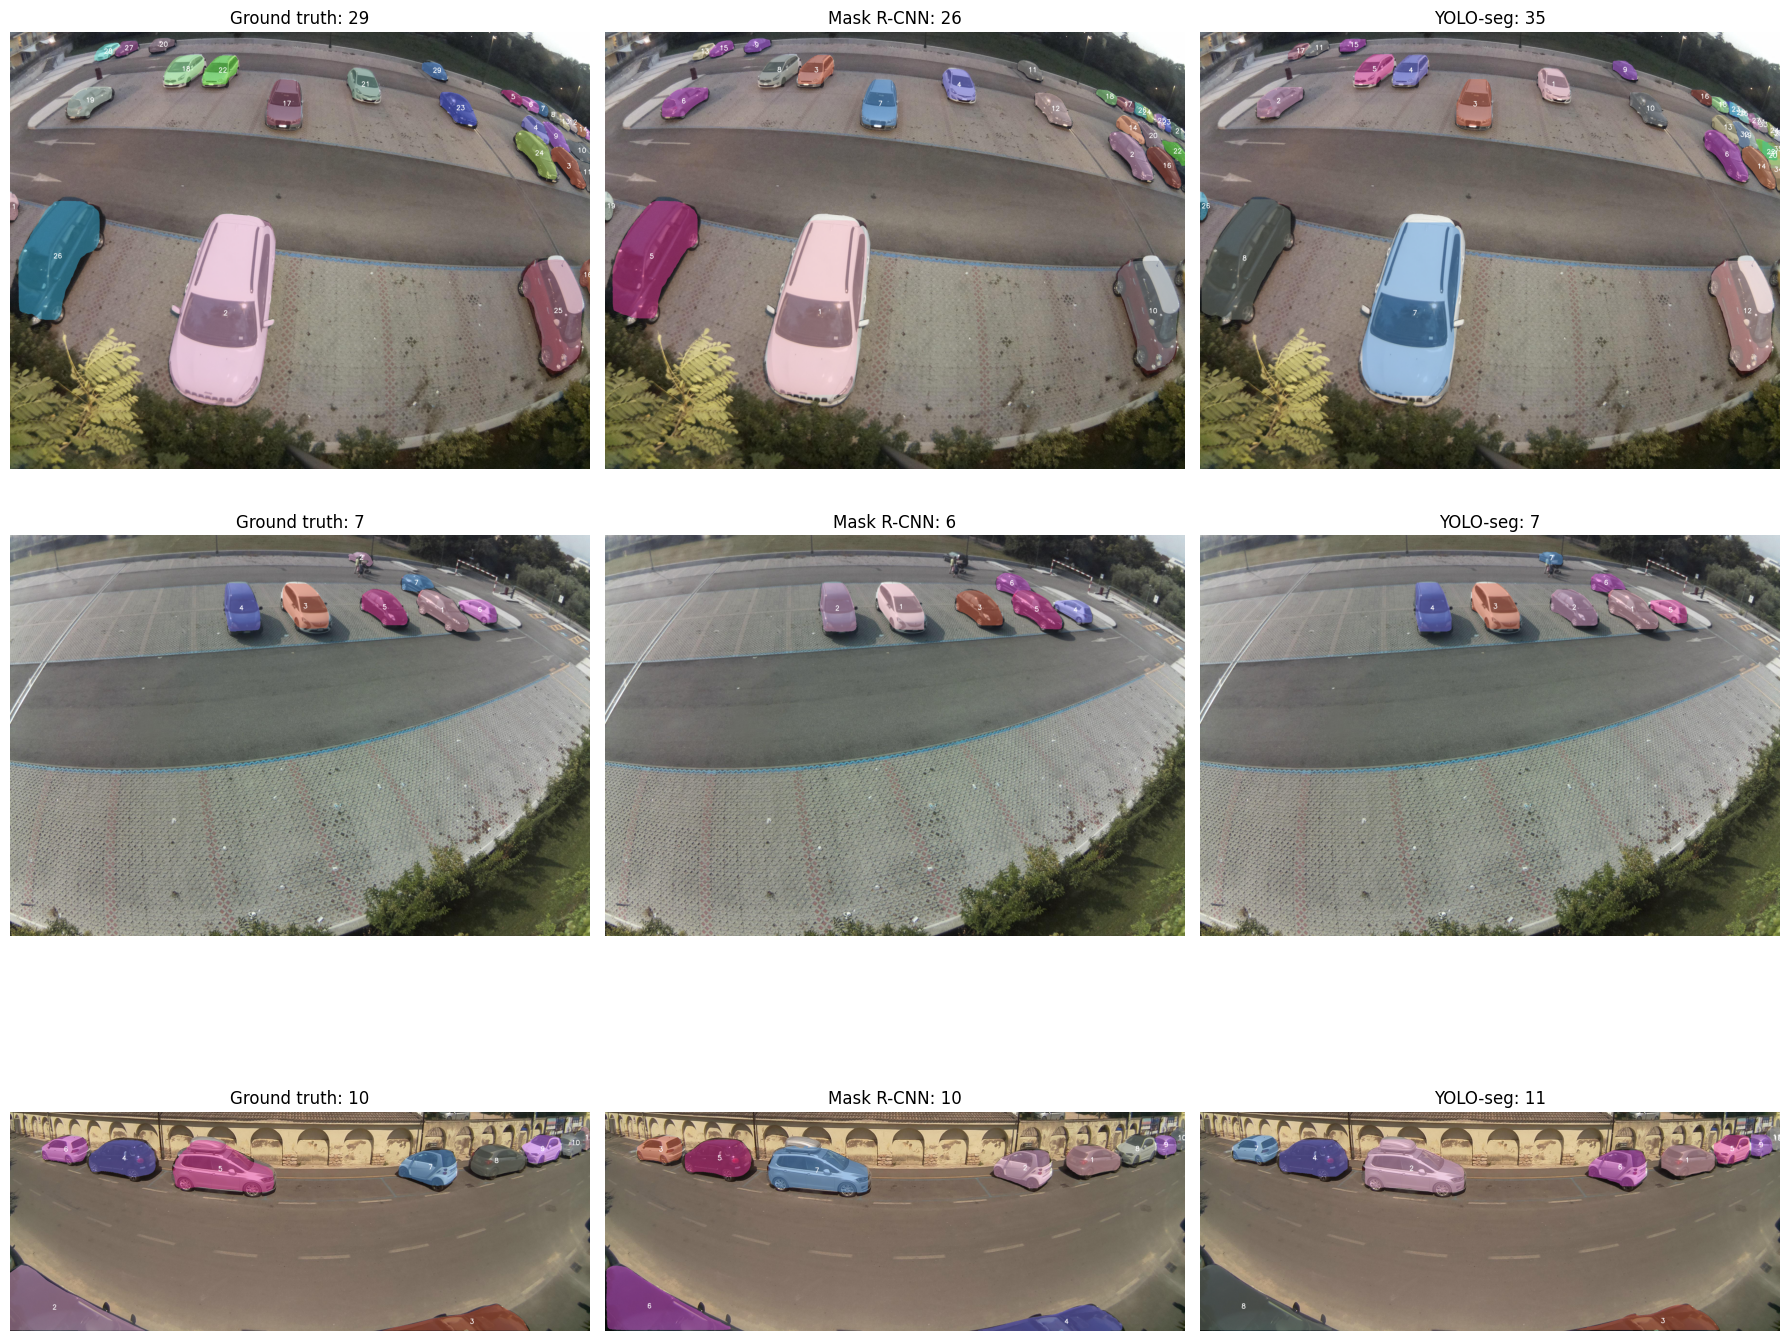

In [ ]:
# visual comparison
def masks_at(pred, thr):
    return [mask_util.decode(r).astype(bool) for r, s in zip(pred["rles"], pred["scores"]) if s >= thr]

show_ids = night_test_ids[:3]
fig, ax = plt.subplots(len(show_ids), 3, figsize=(18, 5 * len(show_ids)))
for r, vid in enumerate(show_ids):
    img = cv2.cvtColor(cv2.imread(path_of(coco_val, vid)), cv2.COLOR_BGR2RGB)
    gt = [coco_val.annToMask(a).astype(bool) for a in coco_val.loadAnns(coco_val.getAnnIds(imgIds=vid))]
    rm = masks_at(rcnn_test[vid], thr_used["Mask R-CNN"])
    ym = masks_at(yolo_test[vid], thr_used["YOLO-seg"])
    ax[r, 0].imshow(draw_instances(img, gt)); ax[r, 0].set_title(f"Ground truth: {len(gt)}")
    ax[r, 1].imshow(draw_instances(img, rm)); ax[r, 1].set_title(f"Mask R-CNN: {len(rm)}")
    ax[r, 2].imshow(draw_instances(img, ym)); ax[r, 2].set_title(f"YOLO-seg: {len(ym)}")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()